# 09 - LightGBM Challenger Models

Train LightGBM on the cleaned data (`02_data_cleaning` output, same train/test split) and compare it with the logistic scorecard.

| Model | Features | Constraint |
|---|---|---|
| **Scorecard** | 16 WoE features (`06_modelling`) | Negative coefficients |
| **LGBM-16** | Same 16 features, raw values | None |
| **LGBM-16-mono** | Same 16 features, raw values | Monotone on numeric features (direction from train) |
| **LGBM-full** | All features | None |

LGBM-16 vs Scorecard isolates the gain from the algorithm; LGBM-full vs LGBM-16 the gain from extra features; LGBM-16-mono shows the cost of keeping risk directions explainable.

Rules:
- **Protected attributes** (`CODE_GENDER`, `NAME_FAMILY_STATUS`) and the ID are excluded, as in the scorecard.
- **The test set is not used for training or tuning**: early stopping uses a validation split carved from train; the final model is refit on the full train set.
- No class weighting, so predicted PDs stay calibrated.

## 1. Setup

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_curve

# Add project root to sys.path so `src` can be imported from the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.evaluation import calibration_table, performance_summary
from src.gbm import (
    DEFAULT_PARAMS,
    category_levels,
    ice_monotone_share,
    monotone_directions,
    prepare_features,
    refit_lgbm,
    train_lgbm,
)
from src.model import predict_pd
from src.split import stratified_split

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

PROTECTED = ["CODE_GENDER", "NAME_FAMILY_STATUS"]
ID_COL, TARGET = "SK_ID_CURR", "TARGET"

# Chart colors: categorical slots 1-4 in fixed order, muted ink for reference lines
COLORS = {"Scorecard": "#2a78d6", "LGBM-16": "#eb6834", "LGBM-16-mono": "#1baf7a", "LGBM-full": "#eda100"}
MUTED, GRID = "#8a8985", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": MUTED,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
})

## 2. Load data

In [2]:
train = pd.read_pickle(DATA_DIR / "train.pkl")
test = pd.read_pickle(DATA_DIR / "test.pkl")
y_train, y_test = train[TARGET], test[TARGET]

FULL = [c for c in train.columns if c not in (TARGET, ID_COL, *PROTECTED)]
SC16 = pd.read_csv(OUTPUT_DIR / "model_features.csv")["feature"].tolist()
levels = category_levels(train[FULL])

# Validation split carved from train (for early stopping only)
fit_df, val_df = stratified_split(train, test_size=0.2, random_state=42)
print(f"Train {train.shape} -> fit {len(fit_df):,} / val {len(val_df):,} | test {len(test):,}")
print(f"Full feature set: {len(FULL)} ({len(levels)} categorical) | scorecard set: {len(SC16)}")

Train (246008, 123) -> fit 196,806 / val 49,202 | test 61,503
Full feature set: 119 (14 categorical) | scorecard set: 16


## 3. Monotone directions (LGBM-16-mono)

Direction per numeric feature from its Spearman correlation with the target on the fit split: `+1` = risk rises with the value, `-1` = risk falls. Categorical features stay unconstrained (`0`). Check that every direction makes business sense.

In [3]:
X_fit16 = prepare_features(fit_df, SC16, levels)
mono16 = monotone_directions(X_fit16, fit_df[TARGET])
pd.Series(mono16, name="direction").map({1: "+1 (risk up)", -1: "-1 (risk down)", 0: "0 (categorical)"}).to_frame()

,direction
EXT_SOURCE_3,-1 (risk down)
EXT_SOURCE_2,-1 (risk down)
EXT_SOURCE_1,-1 (risk down)
YEARS_EMPLOYED,-1 (risk down)
OCCUPATION_TYPE,0 (categorical)
ORGANIZATION_TYPE,0 (categorical)
REGION_RATING_CLIENT_W_CITY,+1 (risk up)
AMT_GOODS_PRICE,-1 (risk down)
NAME_EDUCATION_TYPE,0 (categorical)
YEARS_LAST_PHONE_CHANGE,-1 (risk down)


## 4. Train: early stopping on validation, then refit on full train

The refit uses `best_rounds / 0.8` rounds, since the full train set is 25% larger than the fit split.

In [4]:
VARIANTS = {
    "LGBM-16": (SC16, None),
    "LGBM-16-mono": (SC16, mono16),
    "LGBM-full": (FULL, None),
}

models, log = {}, []
for name, (feats, mono) in VARIANTS.items():
    X_fit = prepare_features(fit_df, feats, levels)
    X_val = prepare_features(val_df, feats, levels)
    early, best = train_lgbm(X_fit, fit_df[TARGET], X_val, val_df[TARGET], DEFAULT_PARAMS, mono)
    val_auc = performance_summary(val_df[TARGET], pd.Series(early.predict_proba(X_val)[:, 1], index=X_val.index))["auc"]
    n_rounds = round(best / 0.8)
    models[name] = refit_lgbm(prepare_features(train, feats, levels), y_train, n_rounds, DEFAULT_PARAMS, mono)
    log.append({"model": name, "n_features": len(feats), "best_rounds": best, "refit_rounds": n_rounds, "val_auc": val_auc})
    print(f"{name}: best {best} rounds, val AUC {val_auc:.4f}")

pd.DataFrame(log).set_index("model").round(4)

LGBM-16: best 291 rounds, val AUC 0.7462
LGBM-16-mono: best 254 rounds, val AUC 0.7407
LGBM-full: best 501 rounds, val AUC 0.7550


,n_features,best_rounds,refit_rounds,val_auc
model,,,,
LGBM-16,16,291,364,0.7462
LGBM-16-mono,16,254,318,0.7407
LGBM-full,119,501,626,0.7550


## 5. Monotonicity check

Share of individual PD curves (feature swept over its range, other features fixed) that follow the expected direction, on 2,000 test rows. LGBM-16-mono must reach 100%; LGBM-16 shows how often an unconstrained model breaks the business logic.

In [5]:
sample = prepare_features(test.sample(2000, random_state=0), SC16, levels)
numeric16 = [f for f, d in mono16.items() if d != 0]
mono_check = pd.DataFrame({
    name: {f: ice_monotone_share(models[name], sample, f, mono16[f]) for f in numeric16}
    for name in ["LGBM-16", "LGBM-16-mono"]
})
assert (mono_check["LGBM-16-mono"] == 1.0).all(), "Monotone constraint violated"
mono_check.style.format("{:.1%}")

,LGBM-16,LGBM-16-mono
EXT_SOURCE_3,32.0%,100.0%
EXT_SOURCE_2,40.2%,100.0%
EXT_SOURCE_1,12.7%,100.0%
YEARS_EMPLOYED,1.4%,100.0%
REGION_RATING_CLIENT_W_CITY,84.9%,100.0%
AMT_GOODS_PRICE,0.0%,100.0%
YEARS_LAST_PHONE_CHANGE,0.1%,100.0%
FLOORSMAX_AVG,10.3%,100.0%
YEARS_ID_PUBLISH,0.0%,100.0%
FLAG_DOCUMENT_3,94.4%,100.0%


## 6. Test-set comparison

- **AUC / Gini / KS**: ranking power. `train_auc` vs `auc` shows overfitting.
- **Brier score**: mean squared error of the PD (lower is better).
- **Calibration**: worst decile ratio of observed default rate / mean PD (1 = perfect).

In [6]:
with open(OUTPUT_DIR / "logit_model.pkl", "rb") as f:
    logit = pickle.load(f)
woe_train = pd.read_pickle(DATA_DIR / "woe_train.pkl")
woe_test = pd.read_pickle(DATA_DIR / "woe_test.pkl")

pd_train = {"Scorecard": predict_pd(logit, woe_train[SC16])}
pd_test = {"Scorecard": predict_pd(logit, woe_test[SC16])}
for name, (feats, _) in VARIANTS.items():
    for df, store in [(train, pd_train), (test, pd_test)]:
        X = prepare_features(df, feats, levels)
        store[name] = pd.Series(models[name].predict_proba(X)[:, 1], index=X.index, name="pd")


def compare(name: str) -> pd.Series:
    """Test metrics of one model."""
    p = pd_test[name]
    ratio = calibration_table(y_test, p)["ratio"]
    return pd.concat([
        performance_summary(y_test, p),
        pd.Series({
            "train_auc": performance_summary(y_train, pd_train[name])["auc"],
            "brier": brier_score_loss(y_test, p),
            "mean_pd": p.mean(),
            "worst_calib_ratio": ratio.iloc[(ratio - 1).abs().argmax()],
        }),
    ])


comparison = pd.DataFrame({name: compare(name) for name in pd_test}).T
comparison["gini_vs_scorecard"] = comparison["gini"] - comparison.loc["Scorecard", "gini"]
print(f"Observed test default rate: {y_test.mean():.4f}")
comparison.round(4)

Observed test default rate: 0.0807


,auc,gini,ks,train_auc,brier,mean_pd,worst_calib_ratio,gini_vs_scorecard
Scorecard,0.7386,0.4772,0.3572,0.7374,0.0691,0.0804,0.9085,0.0000
LGBM-16,0.7509,0.5017,0.3730,0.7832,0.0681,0.0804,1.0776,0.0246
LGBM-16-mono,0.7457,0.4913,0.3634,0.7584,0.0685,0.0805,1.1224,0.0141
LGBM-full,0.7592,0.5183,0.3913,0.8212,0.0676,0.0803,0.8702,0.0412


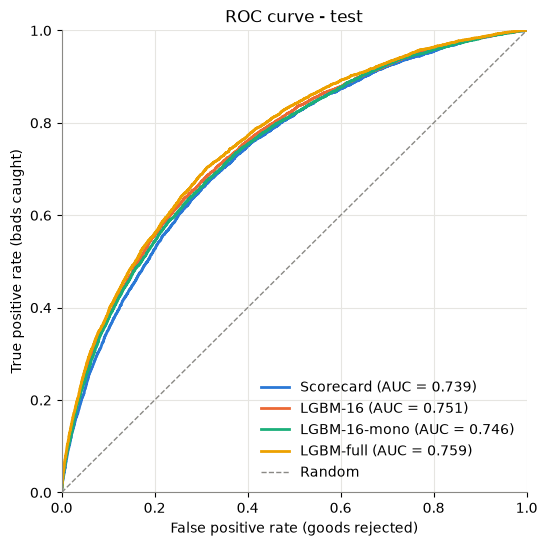

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in pd_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC = {comparison.loc[name, 'auc']:.3f})")
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random")
ax.set(xlabel="False positive rate (goods rejected)", ylabel="True positive rate (bads caught)",
       title="ROC curve - test", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="lower right", frameon=False)
fig.savefig(OUTPUT_DIR / "roc_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# Calibration per decile (ratio = observed default rate / mean PD)
pd.DataFrame({name: calibration_table(y_test, p)["ratio"] for name, p in pd_test.items()}).round(3)

,Scorecard,LGBM-16,LGBM-16-mono,LGBM-full
band,,,,
1,1.018,1.022,1.004,1.005
2,0.995,0.983,0.999,0.997
3,1.036,1.017,1.036,1.031
4,0.990,0.988,1.018,1.025
5,0.968,1.013,0.956,1.034
6,0.967,0.981,0.953,0.990
7,1.002,0.999,1.073,0.956
8,0.909,1.078,0.932,1.065
9,1.078,0.925,0.949,0.870


## 7. Save artifacts

In [9]:
for name, (feats, mono) in VARIANTS.items():
    bundle = {"model": models[name], "features": feats, "levels": levels, "monotone": mono}
    with open(OUTPUT_DIR / f"lgbm_{name.lower().replace('-', '_')}.pkl", "wb") as f:
        pickle.dump(bundle, f)

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv")
pd.DataFrame(pd_test).assign(TARGET=y_test).to_pickle(DATA_DIR / "pd_test_all_models.pkl")
print("Saved lgbm_*.pkl, model_comparison.csv, roc_comparison.png, data/pd_test_all_models.pkl")

Saved lgbm_*.pkl, model_comparison.csv, roc_comparison.png, data/pd_test_all_models.pkl
